# Assignment 8 - NLP
Run **Kernel > Restart & Run All**. Run the install cell first; if it installs anything, restart the kernel once and run all again.

In [1]:
# Install everything needed (run once)
%pip install -q nltk textblob wordcloud scikit-learn pandas matplotlib numpy tensorflow

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

Note: you may need to restart the kernel to use updated packages.


In [1]:
%matplotlib inline
import re
import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist
from nltk.stem import PorterStemmer, WordNetLemmatizer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from textblob import TextBlob
from wordcloud import WordCloud
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

for resource in ['punkt', 'punkt_tab', 'stopwords', 'wordnet', 'omw-1.4']:
    nltk.download(resource, quiet=True)

stop_words = set(stopwords.words('english'))
print("Setup complete")

ModuleNotFoundError: No module named 'tensorflow'

Setup complete


## Q1. Tokenization, stopwords, frequency

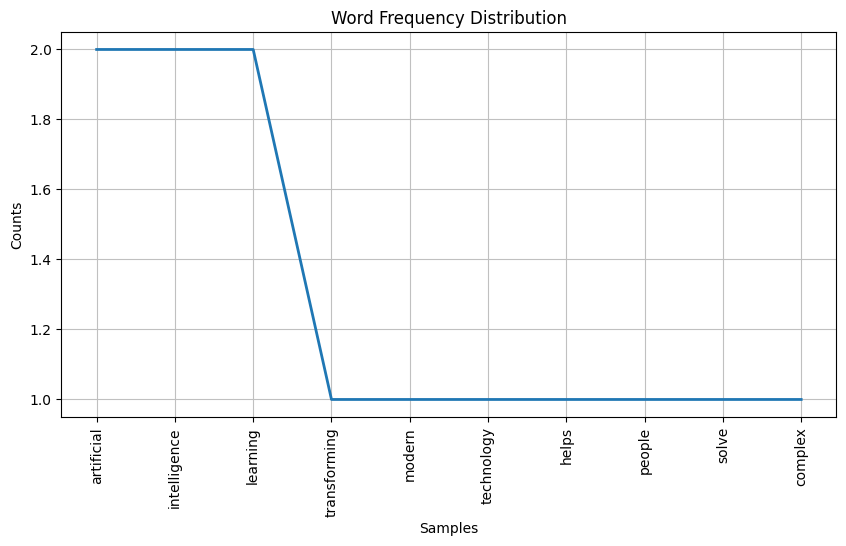

In [ ]:
text = """
Artificial intelligence is transforming modern technology.
It helps people solve complex problems quickly.
Machine learning allows computers to learn from data.
AI applications are useful in education, healthcare, and business.
I enjoy learning artificial intelligence because it encourages creativity.
In the future, intelligent systems may improve everyday life.
"""
clean_text = re.sub(r'[^\w\s]', '', text.lower())

print("Original Text:\n", text)
print("\nCleaned Text:\n", clean_text)

words = word_tokenize(clean_text)
sentences = sent_tokenize(text)

print("\nWord Tokens:", words)
print("\nSentence Tokens:", sentences)
print("\nUsing split():", clean_text.split())
print("\nUsing word_tokenize():", word_tokenize(text.lower()))

filtered_words = [w for w in words if w not in stop_words and w.isalpha()]
print("\nWords after Stopword Removal:", filtered_words)

frequency = FreqDist(filtered_words)
print("\nWord Frequencies:")
print(frequency.most_common())

plt.figure(figsize=(10, 5))
frequency.plot(10, title="Word Frequency Distribution")
plt.show()

## Q2. Stemming and lemmatization

In [4]:
text2 = """Artificial intelligence helps computers understand information.
Students are learning new technologies and building useful applications.
These systems process data, solve problems, and improve services."""

alpha_words = re.findall(r'\b[a-zA-Z]+\b', text2.lower())
filtered = [w for w in alpha_words if w not in stop_words]

stemmer = PorterStemmer()
stemmed = [stemmer.stem(w) for w in filtered]

lemmatizer = WordNetLemmatizer()
lemmatized = [lemmatizer.lemmatize(w) for w in filtered]

print("Alphabetic Words:", alpha_words)
print("After Stopword Removal:", filtered)
print("Stemmed Words:", stemmed)
print("Lemmatized Words:", lemmatized)
print()
for w, s, l in zip(filtered, stemmed, lemmatized):
    print(w, "-> Stem:", s, "| Lemma:", l)

Alphabetic Words: ['artificial', 'intelligence', 'helps', 'computers', 'understand', 'information', 'students', 'are', 'learning', 'new', 'technologies', 'and', 'building', 'useful', 'applications', 'these', 'systems', 'process', 'data', 'solve', 'problems', 'and', 'improve', 'services']
After Stopword Removal: ['artificial', 'intelligence', 'helps', 'computers', 'understand', 'information', 'students', 'learning', 'new', 'technologies', 'building', 'useful', 'applications', 'systems', 'process', 'data', 'solve', 'problems', 'improve', 'services']
Stemmed Words: ['artifici', 'intellig', 'help', 'comput', 'understand', 'inform', 'student', 'learn', 'new', 'technolog', 'build', 'use', 'applic', 'system', 'process', 'data', 'solv', 'problem', 'improv', 'servic']
Lemmatized Words: ['artificial', 'intelligence', 'help', 'computer', 'understand', 'information', 'student', 'learning', 'new', 'technology', 'building', 'useful', 'application', 'system', 'process', 'data', 'solve', 'problem', 'i

## Q3. Bag of Words and TF-IDF

In [5]:
texts = [
    "Artificial intelligence improves healthcare and education.",
    "Machine learning helps computers analyze data and make predictions.",
    "Blockchain provides secure and transparent digital transactions."
]

cv = CountVectorizer()
bow = cv.fit_transform(texts)
print("Bag of Words:")
print(pd.DataFrame(bow.toarray(), columns=cv.get_feature_names_out()))

tfidf = TfidfVectorizer(stop_words='english')
matrix = tfidf.fit_transform(texts)
features = tfidf.get_feature_names_out()

print("\nTF-IDF Scores:")
print(pd.DataFrame(matrix.toarray(), columns=features).round(3))

for i, row in enumerate(matrix.toarray()):
    top = row.argsort()[-3:][::-1]
    print(f"\nText {i+1} Top 3 Keywords:")
    for idx in top:
        print(features[idx], round(row[idx], 3))

Bag of Words:
   analyze  and  artificial  blockchain  computers  data  digital  education  \
0        0    1           1           0          0     0        0          1   
1        1    1           0           0          1     1        0          0   
2        0    1           0           1          0     0        1          0   

   healthcare  helps  improves  intelligence  learning  machine  make  \
0           1      0         1             1         0        0     0   
1           0      1         0             0         1        1     1   
2           0      0         0             0         0        0     0   

   predictions  provides  secure  transactions  transparent  
0            0         0       0             0            0  
1            1         0       0             0            0  
2            0         1       1             1            1  

TF-IDF Scores:
   analyze  artificial  blockchain  computers   data  digital  education  \
0    0.000       0.447       0.0

## Q4. Jaccard and Cosine similarity

In [6]:
doc1 = """Artificial intelligence enables machines to learn from data.
It supports automation, prediction, and intelligent decision making.
AI is widely used in healthcare, education, and robotics."""

doc2 = """Blockchain stores information in secure distributed digital records.
It supports transparency, security, and decentralized transactions.
Blockchain is widely used in finance and digital applications."""

def preprocess(t):
    return re.sub(r'[^a-zA-Z\s]', '', t.lower()).split()

tokens1 = preprocess(doc1)
tokens2 = preprocess(doc2)

print("AI Tokens:", tokens1)
print("Blockchain Tokens:", tokens2)

set1, set2 = set(tokens1), set(tokens2)
jaccard = len(set1 & set2) / len(set1 | set2)
print("\nJaccard Similarity:", round(jaccard, 3))

vectorizer = TfidfVectorizer(stop_words='english')
vectors = vectorizer.fit_transform([doc1, doc2])
cosine = cosine_similarity(vectors[0:1], vectors[1:2])[0][0]
print("Cosine Similarity:", round(cosine, 3))

AI Tokens: ['artificial', 'intelligence', 'enables', 'machines', 'to', 'learn', 'from', 'data', 'it', 'supports', 'automation', 'prediction', 'and', 'intelligent', 'decision', 'making', 'ai', 'is', 'widely', 'used', 'in', 'healthcare', 'education', 'and', 'robotics']
Blockchain Tokens: ['blockchain', 'stores', 'information', 'in', 'secure', 'distributed', 'digital', 'records', 'it', 'supports', 'transparency', 'security', 'and', 'decentralized', 'transactions', 'blockchain', 'is', 'widely', 'used', 'in', 'finance', 'and', 'digital', 'applications']

Jaccard Similarity: 0.189
Cosine Similarity: 0.082


## Q5. Sentiment analysis and word cloud


Review: This laptop is excellent and performs very fast.
Polarity: 0.63
Subjectivity: 0.89
Classification: Positive

Review: The product quality is amazing and the battery lasts long.
Polarity: 0.275
Subjectivity: 0.65
Classification: Positive

Review: The service was terrible and the product stopped working.
Polarity: -1.0
Subjectivity: 1.0
Classification: Negative

Review: Very disappointing purchase with poor customer support.
Polarity: -0.59
Subjectivity: 0.755
Classification: Negative

Review: The product is okay and works as expected.
Polarity: 0.2
Subjectivity: 0.45
Classification: Positive

Review: The service was average and nothing special.
Polarity: 0.104
Subjectivity: 0.486
Classification: Positive


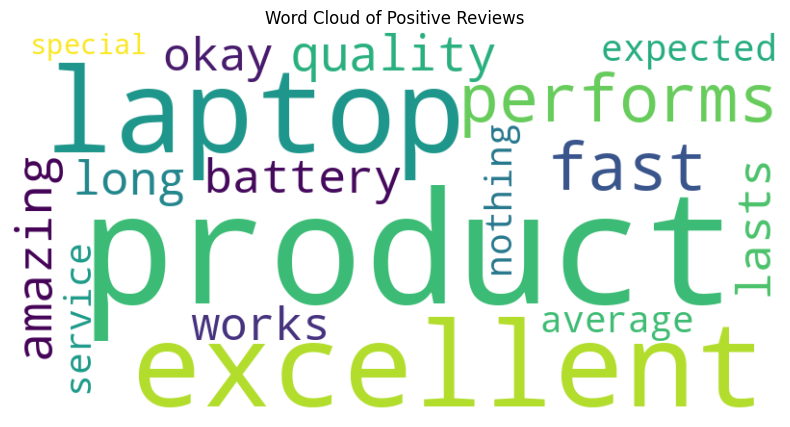

In [7]:
reviews = [
    "This laptop is excellent and performs very fast.",
    "The product quality is amazing and the battery lasts long.",
    "The service was terrible and the product stopped working.",
    "Very disappointing purchase with poor customer support.",
    "The product is okay and works as expected.",
    "The service was average and nothing special."
]

positive_reviews = []

for review in reviews:
    sentiment = TextBlob(review).sentiment
    polarity = sentiment.polarity
    subjectivity = sentiment.subjectivity

    if polarity > 0.1:
        label = "Positive"
        positive_reviews.append(review)
    elif polarity < -0.1:
        label = "Negative"
    else:
        label = "Neutral"

    print("\nReview:", review)
    print("Polarity:", round(polarity, 3))
    print("Subjectivity:", round(subjectivity, 3))
    print("Classification:", label)

if not positive_reviews:          # safety: avoid WordCloud error on empty text
    positive_reviews = reviews
positive_text = " ".join(positive_reviews)

cloud = WordCloud(width=800, height=400, background_color="white",
                  collocations=False).generate(positive_text)

plt.figure(figsize=(10, 5))
plt.imshow(cloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of Positive Reviews")
plt.show()

## Q6. LSTM text generation

In [8]:
tf.keras.utils.set_random_seed(42)

text3 = """Artificial intelligence is changing the modern world.
It helps students learn new concepts and solve difficult problems.
Machine learning allows computers to identify patterns in data.
Deep learning is used in image recognition and natural language processing.
Technology supports healthcare, education, agriculture, and transportation.
Developers create intelligent applications to improve everyday life.
Data is important because artificial intelligence learns from examples.
Researchers develop safer and more reliable intelligent systems.
Students can learn these technologies through practice and experimentation.
In the future, artificial intelligence may support many human activities.
Understanding technology helps people prepare for new opportunities.
Responsible innovation can make digital systems more useful for society."""

tokenizer = Tokenizer()
tokenizer.fit_on_texts([text3])
token_list = tokenizer.texts_to_sequences([text3])[0]
total_words = len(tokenizer.word_index) + 1

sequences = [token_list[:i+1] for i in range(1, len(token_list))]
max_len = max(len(seq) for seq in sequences)
sequences = pad_sequences(sequences, maxlen=max_len, padding='pre')

X = sequences[:, :-1]
y = tf.keras.utils.to_categorical(sequences[:, -1], num_classes=total_words)

model = Sequential([
    Embedding(total_words, 50),
    LSTM(100),
    Dense(total_words, activation='softmax')
])
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

history = model.fit(X, y, epochs=200, verbose=0)
print("LSTM Model Trained Successfully")
print("Final training accuracy:", round(history.history['accuracy'][-1], 3))

index_word = {i: w for w, i in tokenizer.word_index.items()}

def generate_text(seed, next_words=10):
    result = seed
    for _ in range(next_words):
        seq = tokenizer.texts_to_sequences([result])[0]
        seq = pad_sequences([seq], maxlen=max_len - 1, padding='pre')
        prediction = model.predict(seq, verbose=0)
        word_id = int(np.argmax(prediction, axis=1)[0])
        output_word = index_word.get(word_id)
        if output_word is None:
            break
        result += " " + output_word
    return result

for seed in ["artificial intelligence", "machine learning", "technology"]:
    print(generate_text(seed, 10) + ".")

LSTM Model Trained Successfully
Final training accuracy: 0.99


artificial intelligence is changing the modern world it helps students learn new.


machine learning is changing the modern world it helps students learn new.


technology is changing the modern world world it helps students learn.
